# **Sesión 2:** Calibración de Cámara 📷⚙️

## 0. Preparación

In [14]:
import cv2
print("OpenCV should be 4.8.x Current version:", cv2.__version__)
from typing import List
import numpy as np
# import imageio --- IGNORE IF DEPRECATED---
import imageio.v3 as imageio
import copy
import os
import glob
import matplotlib.pyplot as plt


OpenCV should be 4.8.x Current version: 4.8.0


## **Apartado A: Calibración de cámara** (derecha e izquierda)

En este apartado se realiza la calibración de dos cámaras de un sistema estereoscópico. Para ello se trabajará con las imágenes de las carpetas ``left`` y ``right``. En primer lugar se trabajará con la carpeta ``left``. Posteriormente, deberá repetir el proceso con las imágenes en la carpeta ``right``. Ambas carpetas contienen imágenes con las que se calibrarán las cámaras. En ellas aparece el patrón de calibración en diferentes posiciones y orientaciones. Estas imágenes serán los datos de entrada.

Los pasos que deberá seguir para calibrar una cámara son:

1. Defina y ejecute el método para cargar imágenes ``load_images()``.
2. Detecte las esquinas de los patrones usando ``cv2.findChessboardCorners()``. Refine las detecciones con ``cv2.cornerSubPix()``.
3. Compruebe que las detecciones son correctas dibujando los resultados con ``cv2.drawChessboardCorners()``.
4. Defina y ejecute el método ``get_chessboard_points(chessboard_shape, dx, dy)`` que proporcione las coordenadas 3D de las esquinas del patrón. El sistema de referencia utilizado deberá estar anclado al propio patrón.
5. Utilice ``cv2.calibrateCamera`` para obtener los parámetros de calibración para la cámara izquierda.

### **Tarea A.1:** Defina y ejecute el método para cargar imágenes ``load_images()``.

In [3]:
def load_images(filenames: List) -> List:
    return [cv2.imread(filename) for filename in filenames]

In [3]:
# TODO Build a list containing the paths of all images from the left camera
imgs_path = []
from pathlib import Path
carpeta = Path('../data2/left')
for archivo in carpeta.iterdir():
    if archivo.is_file() and archivo.name != ".DS_Store":
        imgs_path.append(f"../data2/left/{archivo.name}")
imgs = load_images(imgs_path)

### **Tarea A.2:** Detecte las esquinas de los patrones usando ``cv2.findChessboardCorners()``. Refine las detecciones con ``cv2.cornerSubPix()``.

In [ ]:
# TODO Find corners with cv2.findChessboardCorners()
# Hint: you can use a list comprehension to process all images
pattern_size = (8,6)
corners = [cv2.findChessboardCorners(img,pattern_size) for img in imgs]

In [ ]:
corners_copy = copy.deepcopy(corners)
criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 30, 0.01)

# TODO To refine corner detections with cv2.cornerSubPix() you need to input grayscale images. Build a list containing grayscale images.
imgs_gray = [cv2.cvtColor(img,cv2.COLOR_BGR2GRAY) for img in imgs]

corners_refined = [
    cv2.cornerSubPix(imgs_gray[i], corners[i][1], [11, 11], [-1, -1], criteria) 
    if corners[i][0] else None 
    for i in range(len(imgs))
]

### **Tarea A.3:** Compruebe que las detecciones son correctas dibujando los resultados con ``cv2.drawChessboardCorners()``

In [6]:
imgs_copy = copy.deepcopy(imgs)

In [7]:
# TODO Use cv2.drawChessboardCorners() to draw the cornes
for i in range(len(imgs_copy)):
    imgs_copy[i] = cv2.drawChessboardCorners(imgs_copy[i], pattern_size, corners_refined[i], patternWasFound = corners[i][0])

In [10]:
# TODO Show images and save when needed

def show_image(img: np.array, img_name: str = "Image"):
    cv2.imshow(img_name,img)
    cv2.waitKey(1000)
    cv2.destroyAllWindows()

# TODO Complete the method, use every argument
def write_image(output_folder: str, img_name: str, img: np.array):
    img_path = os.path.join(output_folder,img_name)
    cv2.imwrite(img_path,img)

# for i in range(len(imgs_copy)):
#     show_image(imgs_copy[i])
#     write_image("../data2/left",f"Imagen{i}.png",imgs_copy[i])



### **Tarea A.4:** Defina y ejecute el método ``get_chessboard_points(chessboard_shape, dx, dy)``

In [7]:
# TODO 
def get_chessboard_points(chessboard_shape, dx, dy):
    cols, rows = chessboard_shape  
    points = []
    for r in range(rows):
        for c in range(cols):
            points.append([c * dx, r * dy, 0])
    return np.array(points, dtype=np.float32)

In [8]:
# TODO You need the points for every image, not just one (consider a list comprehension)
dx = dy = 30
chessboard_points = get_chessboard_points(pattern_size,dx,dy)

### **Tarea A.5:** Utilice ``cv2.calibrateCamera()`` para obtener los parámetros de calibración para la cámara izquierda

In [11]:
# Filter data and get only those with adequate detections
valid_corners = [corners_refined[i] for i in range(len(imgs)) if corners[i][0]]
objpoints = [chessboard_points for _ in valid_corners]
# Convert list to numpy array with np.float32 elements
valid_corners = np.array(valid_corners,dtype=np.float32)

In [12]:
# TODO
img_size = imgs_gray[0].shape[::-1]
rms, intrinsics, dist_coeffs, rvecs, tvecs = cv2.calibrateCamera(objpoints,valid_corners,img_size,None,None)

# Obtain extrinsics
extrinsics = list(map(lambda rvec, tvec: np.hstack((cv2.Rodrigues(rvec)[0], tvec)), rvecs, tvecs))

In [13]:
# Print outputs
print("Intrinsics:\n", intrinsics)
print("Distortion coefficients:\n", dist_coeffs)
print("Root mean squared reprojection error:\n", rms)

Intrinsics:
 [[300.68650679   0.         109.08335383]
 [  0.         305.09232347 204.51791996]
 [  0.           0.           1.        ]]
Distortion coefficients:
 [[-0.17373223  0.90121659 -0.00700206 -0.0219272  -1.58027117]]
Root mean squared reprojection error:
 2.0357251440636226


### **Pregunta A.1:** Repita el proceso (carga de imágenes, detección y comprobación de esquinas, etc.) para la cámara derecha.

In [13]:
# TODO Homework
imgs_path = []
from pathlib import Path
carpeta = Path('../data2/right')
for archivo in carpeta.iterdir():
    if archivo.is_file() and archivo.name != ".DS_Store":
        imgs_path.append(f"../data2/right/{archivo.name}")
imgs_right = load_images(imgs_path)
pattern_size = (8,6)
corners = [cv2.findChessboardCorners(img,pattern_size) for img in imgs_right]
corners_copy = copy.deepcopy(corners)
criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 30, 0.01)

imgs_gray = [cv2.cvtColor(img,cv2.COLOR_BGR2GRAY) for img in imgs_right]

corners_refined = [
    cv2.cornerSubPix(imgs_gray[i], corners[i][1], [11, 11], [-1, -1], criteria) 
    if corners[i][0] else None 
    for i in range(len(imgs_right))
]
imgs_copy = copy.deepcopy(imgs_right)
for i in range(len(imgs_copy)):
    imgs_copy[i] = cv2.drawChessboardCorners(imgs_copy[i], pattern_size, corners_refined[i], patternWasFound = corners[i][0])
for i in range(len(imgs_copy)):
    show_image(imgs_copy[i])
    write_image("../data2/right",f"Imagen{i}.png",imgs_copy[i])
valid_corners = [corners_refined[i] for i in range(len(imgs_right)) if corners[i][0]]
objpoints = [chessboard_points for _ in valid_corners]
# Convert list to numpy array with np.float32 elements
valid_corners = np.array(valid_corners,dtype=np.float32)
# TODO
img_size = imgs_gray[0].shape[::-1]
rms, intrinsics, dist_coeffs, rvecs, tvecs = cv2.calibrateCamera(objpoints,valid_corners,img_size,None,None)

# Obtain extrinsics
extrinsics = list(map(lambda rvec, tvec: np.hstack((cv2.Rodrigues(rvec)[0], tvec)), rvecs, tvecs))
print("Intrinsics:\n", intrinsics)
print("Distortion coefficients:\n", dist_coeffs)
print("Root mean squared reprojection error:\n", rms)

Intrinsics:
 [[395.67256607   0.         152.88506384]
 [  0.         408.64481622 178.79386168]
 [  0.           0.           1.        ]]
Distortion coefficients:
 [[-0.38390872  1.45904321 -0.01182282 -0.01307509 -3.15472506]]
Root mean squared reprojection error:
 1.3288127646374208


### **Pregunta A.2:** Diferencias entre cv2.findChessboardCorners() y cv2.cornerSubPix()

En esta práctica utilizamos dos funciones con un objetivo similar pero con ciertas diferencias. Estas funciones son cv2.findChessboardCorners() y cv2.cornerSubPix(). La primera se utiliza para encontrar el patrón del tablero de ajedrez y las coordenadas de sus esquinas con una precisión de píxel. La segunda recibe estas coordenadas y mejora la aproximación de la posición de las esquinas con una precisión subpíxel. 

### **Pregunta A.3:** Número mínimo de imágenes necesarias para calibrar.

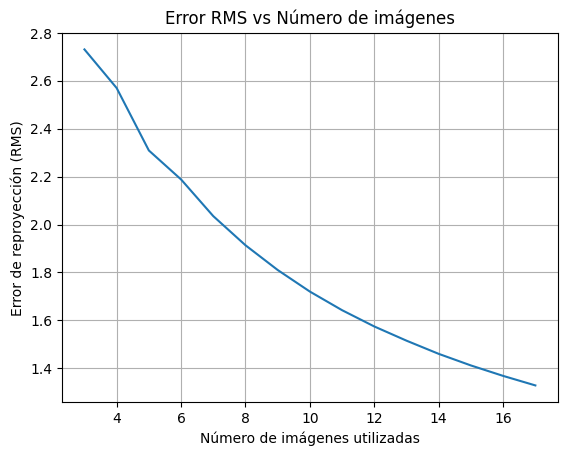

In [17]:
# TODO Homework
eje_x = [] #Número imágenes utilizadas
eje_y = [] #Error calibración resultante

for i in range(3,len(valid_corners)+1):
    obj_recortado = objpoints[:i]
    valid_recortado = valid_corners[:i]
    rms, intrinsics, dist_coeffs, rvecs, tvecs = cv2.calibrateCamera(obj_recortado,valid_recortado,img_size,None,None)
    eje_x.append(i)
    eje_y.append(rms)

plt.plot(eje_x, eje_y)
plt.title('Error RMS vs Número de imágenes')
plt.xlabel('Número de imágenes utilizadas')
plt.ylabel('Error de reproyección (RMS)')
plt.grid()
plt.show()


## **Apartado B: Corrección de distorsión** (ojo de pez)

En este apartado se trabajará en la corrección de la distorsión debido a lentes de ojo de pez. Primero se calibrará una cámara con este tipo de lente, utilizando las imágenes de la carpeta ``fisheye``. Posteriormente se utilizarán estos parámetros de calibración para corregir la distorsión de una de las imágenes de calibración.

Los pasos que deberá seguir para calibrar una cámara con distorsión de ojo de pez son:

1. Reutilice el método ``load_images()`` para cargar las imágenes de la carpeta ``fisheye``.
2. Detecte las equinas procesando las imágenes con los métodos ``cv2.findChessboardCorners()`` y ``cv2.cornerSubPix()``.
3. Reutilice la función ``get_chessboard_points()`` para obtener las coordenadas del tablero.
4. Defina los argumentos para la función de calibración.
5. Calibre con ``cv2.fisheye.calibrate()``

### **Tarea B.1:** Reutilice el método ``load_images()`` para cargar las imágenes de la carpeta ``fisheye``

In [18]:
# TODO Build a list containing the paths of all images from the fisheye camera and load images
fisheye_imgs_path = []
from pathlib import Path
carpeta = Path('../data2/fisheye')
for archivo in carpeta.iterdir():
    if archivo.is_file() and archivo.name != ".DS_Store":
        fisheye_imgs_path.append(f"../data2/fisheye/{archivo.name}")
fisheye_imgs = load_images(fisheye_imgs_path)

### **Tarea B.2:** Detecte las equinas procesando las imágenes con los métodos ``cv2.findChessboardCorners()`` y ``cv2.cornerSubPix()``.

In [19]:
imgs_corners = []
# Parameters for cv2.cornerSubPix()
subpix_criteria = (cv2.TERM_CRITERIA_EPS+cv2.TERM_CRITERIA_MAX_ITER, 30, 0.1)

pattern_size = (7, 6) # Ajustar si el tablero fisheye es de otro tamaño

#TODO Complete the required parts of the loop
for img in fisheye_imgs:
    
    # 1. TODO convert image to grayscale to use cv2.cornerSubPix()
    gray_img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    
    # 2. TODO parse arguments to cv2.findChessboardCorners()
    ret, corners = cv2.findChessboardCorners(gray_img, pattern_size)
    
    # 3. TODO append only those refined_corners with proper detections
    if ret == True:
        refined_corners = cv2.cornerSubPix(gray_img, corners, (3,3), (-1,-1), subpix_criteria)
        imgs_corners.append(refined_corners)

### **Tarea B.3:** Reutilice la función ``get_chessboard_points()`` para obtener las coordenadas del tablero

In [23]:
# TODO Define the chessboard dimensions and the lenght of the squares (in [mm])
chessboard_dims = (7, 6)
length = 30
# TODO You need the points for every image, not just one (consider a list comprehension)
points = get_chessboard_points(chessboard_dims, length, length)
points = points.reshape(1, -1, 3)
# TODO You need the points for every image, not just one (consider a list comprehension)
fisheye_chessboard_points = [points for _ in imgs_corners]
imgs_corners_fisheye = [esquinas.reshape(1, -1, 2) for esquinas in imgs_corners]

### **Tarea B.4:** Defina los argumentos para la calibración

In [24]:
# Parameters for cv2.fisheye.calibrate()
#Calibration_flags ordena que recalcule pos lente a tablero ajedrez+bloquea inclinación
calibration_flags = cv2.fisheye.CALIB_RECOMPUTE_EXTRINSIC+cv2.fisheye.CALIB_FIX_SKEW
intrinsics = np.zeros((3, 3),dtype=np.float64)
distortion = np.zeros((4, 1),dtype=np.float64)
rotations = [np.zeros((1, 1, 3), dtype=np.float64) for _ in imgs_corners]
traslations = [np.zeros((1, 1, 3), dtype=np.float64) for _ in imgs_corners]


### **Tarea B.5:** Calibración

In [25]:
rms, intrinsics, distortion, rvecs, tvecs = \
cv2.fisheye.calibrate(fisheye_chessboard_points, imgs_corners, gray_img.shape[::-1], intrinsics, distortion, rotations, traslations, calibration_flags, subpix_criteria)

In [26]:
# Show intrinsic matrix and distortion coefficients values
print(intrinsics)
print(distortion)
print(rms)

[[188.86914026   0.         503.92900347]
 [  0.         185.32638678 373.58044468]
 [  0.           0.           1.        ]]
[[ 0.07734388]
 [ 0.01482361]
 [ 0.02351869]
 [-0.02757565]]
136.8425931206207


### **Pregunta B.1:** Corrija la distorsión de las 2 primeras imágenes de la carpeta ``fisheye``

In [ ]:
# TODO Search in the documentation to define 'dim'
dim = (fisheye_imgs[0].shape[1],fisheye_imgs[0].shape[0])
map1, map2 = cv2.fisheye.initUndistortRectifyMap(intrinsics, distortion, np.eye(3), intrinsics, dim, cv2.CV_16SC2)

In [ ]:
# TODO Homework: correct distortion using cv2.remap()

corrected_images=[]
for img in fisheye_imgs:
    corrected_distortion = cv2.remap(img, map1, map2,interpolation=cv2.INTER_LINEAR,borderMode=cv2.BORDER_CONSTANT)
    corrected_images.append(corrected_distortion)
n=0
for img in corrected_images:
    show_image(img)
    write_image("../data/corrected/corrected"+str(n)+".jpg",img)
    n+=1